# Evaluating classifiers for rare fraud

## Purpose

Use a synthetic fraud-detection problem to see why accuracy can be misleading when the positive class is rare, compare class-specific metrics and probability rankings, and choose a decision threshold using explicit error costs.

## Contents

1. [Create the rare-event dataset](#create-the-rare-event-dataset)
2. [Accuracy and class-specific metrics](#accuracy-and-class-specific-metrics)
3. [Compare probability models](#compare-probability-models)
4. [Precision-recall and ROC curves](#precision-recall-and-roc-curves)
5. [Choose a threshold using costs](#choose-a-threshold-using-costs)
6. [Final test evaluation](#final-test-evaluation)
7. [Tuning models responsibly](#tuning-models-responsibly)
8. [Takeaways](#takeaways)

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier

paired = plt.get_cmap("Paired").colors
MODEL_COLORS = {
    "Decision tree": paired[1],
    "Random forest": paired[3],
    "Gaussian Naive Bayes": paired[5],
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

## Create the rare-event dataset

Fraud is the positive class (`1`). We create numeric features with an imperfect signal and set the prevalence to exactly 0.4%. This is synthetic data: it is designed to illustrate evaluation, not to represent a real fraud system.

In [10]:
X, y = make_classification(
    n_samples=50_000,
    n_features=6,
    n_informative=4,
    n_redundant=1,
    n_clusters_per_class=1,
    weights=[0.996, 0.004],
    flip_y=0.0,
    class_sep=0.8,
    random_state=42,
)

fraud_count = int(y.sum())
print(f"Transactions: {len(y):,}")
print(f"Fraud cases: {fraud_count:,} ({y.mean():.1%})")



Transactions: 50,000
Fraud cases: 200 (0.4%)


## Accuracy and class-specific metrics

**Predict.** What accuracy would a model get if it labeled every transaction as non-fraud? How many fraud cases would it find?

In [11]:
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.50, stratify=y_holdout, random_state=43
)

print(f"Train: {len(y_train):,} rows, {int(y_train.sum())} fraud")
print(f"Validation: {len(y_val):,} rows, {int(y_val.sum())} fraud")
print(f"Test: {len(y_test):,} rows, {int(y_test.sum())} fraud")

Train: 30,000 rows, 120 fraud
Validation: 10,000 rows, 40 fraud
Test: 10,000 rows, 40 fraud


In [5]:
majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(X_train, y_train)
majority_predictions = majority_model.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, majority_predictions, labels=[0, 1]).ravel()
majority_results = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, majority_predictions),
    "Fraud precision": precision_score(y_test, majority_predictions, zero_division=0),
    "Fraud recall": recall_score(y_test, majority_predictions, zero_division=0),
    "F1": f1_score(y_test, majority_predictions, zero_division=0),
    "MCC": matthews_corrcoef(y_test, majority_predictions),
    "TN": tn, "FP": fp, "FN": fn, "TP": tp,
}])
majority_results

,Accuracy,Fraud precision,Fraud recall,F1,MCC,TN,FP,FN,TP
0,0.996,0.0,0.0,0.0,0.0,9960,0,40,0


Accuracy counts all correct predictions, so the many non-fraud cases dominate it. For the positive class (fraud):

- **Precision** = $\frac{TP}{TP+FP}$: among flagged transactions, how many are fraud?
- **Recall** = $\frac{TP}{TP+FN}$: among fraud cases, how many did we find?
- **F1** = $2\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$: a harmonic mean of precision and recall.
- **MCC** = $\frac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}$: a correlation-style summary using all four confusion-matrix cells.

Precision, recall, F1, and MCC depend on the classification threshold. F1 omits true negatives and does not encode the costs of errors. MCC uses all four cells, but it does not encode those costs either.

**Takeaway.** High accuracy can coexist with zero fraud detection when the positive class is rare. Always inspect the confusion matrix and metrics for the class that matters.

## Compare probability models

Each model returns a score through `predict_proba`. At threshold 0.5, a score at least 0.5 is labeled fraud. We compare a single decision tree, a random forest, and Gaussian Naive Bayes.

In [12]:
models = {
    "Decision tree": DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=10, random_state=42
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=120, min_samples_leaf=3, n_jobs=-1, random_state=42
    ),
    "Gaussian Naive Bayes": GaussianNB(),
}

validation_scores = {}
default_threshold_results = []
for model_name, model in models.items():
    model.fit(X_train, y_train)
    scores = model.predict_proba(X_val)[:, 1]
    validation_scores[model_name] = scores
    predictions = (scores >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()
    default_threshold_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "MCC": matthews_corrcoef(y_val, predictions),
        "False positives": fp,
        "False negatives": fn,
    })

pd.DataFrame(default_threshold_results).set_index("Model").round(3)

,Accuracy,Precision,Recall,F1,MCC,False positives,False negatives
Model,,,,,,,
Decision tree,0.996,0.550,0.275,0.367,0.387,9,29
Random forest,0.997,0.900,0.225,0.360,0.449,1,31
Gaussian Naive Bayes,0.997,0.818,0.225,0.353,0.428,2,31


**Check.** Which model has the best F1 at 0.5? Does that also make it best for the stated fraud-detection costs?

## Precision-recall and ROC curves

These curves vary the decision threshold while measuring how the models rank examples. The dashed precision baseline is the fraud prevalence. With rare positives, precision-recall curves foreground the fraction of alerts that are genuine fraud; ROC curves answer a different question about true-positive rate versus false-positive rate.

**Predict.** With only 0.4% fraud, where would you expect random ranking to sit on the precision-recall plot?

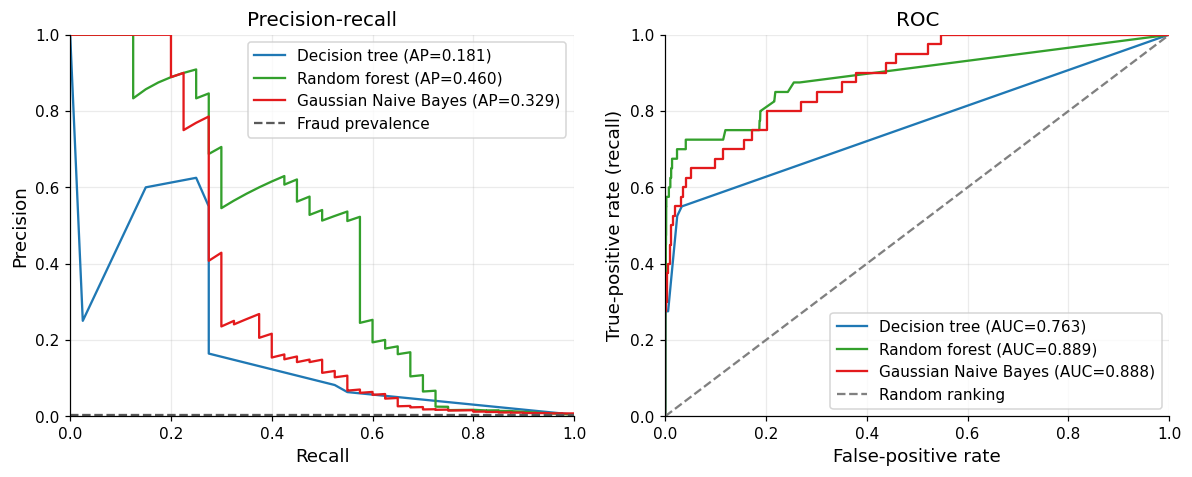

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for model_name, scores in validation_scores.items():
    precision, recall, _ = precision_recall_curve(y_val, scores)
    axes[0].plot(
        recall, precision,
        label=f"{model_name} (AP={average_precision_score(y_val, scores):.3f})",
        color=MODEL_COLORS[model_name],
    )
    fpr, tpr, _ = roc_curve(y_val, scores)
    axes[1].plot(
        fpr, tpr,
        label=f"{model_name} (AUC={roc_auc_score(y_val, scores):.3f})",
        color=MODEL_COLORS[model_name],
    )

axes[0].axhline(y_val.mean(), color="0.35", linestyle="--", label="Fraud prevalence")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall", xlim=(0, 1), ylim=(0, 1))
axes[1].plot([0, 1], [0, 1], color="0.5", linestyle="--", label="Random ranking")
axes[1].set(xlabel="False-positive rate", ylabel="True-positive rate (recall)", title="ROC", xlim=(0, 1), ylim=(0, 1))
axes[0].legend(loc="upper right")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

PR is often more revealing for a rare positive class, but it is not universally better than ROC. ROC is useful when false-positive rate is itself the operational constraint and for comparing ranking performance across thresholds. With very many non-fraud examples, however, a small false-positive rate can still create a large number of false alerts. Average precision summarizes the PR curve; it should not be confused with every possible numerical definition of PR area.

**Takeaway.** Use the curve that matches the question. For rare fraud, always read precision alongside recall and the expected number of alerts.

## Choose a threshold using costs

Suppose a missed fraud costs 100 units and a false alert costs 1 unit. These are illustrative relative costs, not real monetary estimates. We choose a threshold using the validation set only, then freeze it before looking at test results.

Validation-selected threshold: 0.026
Validation cost per transaction: 0.143


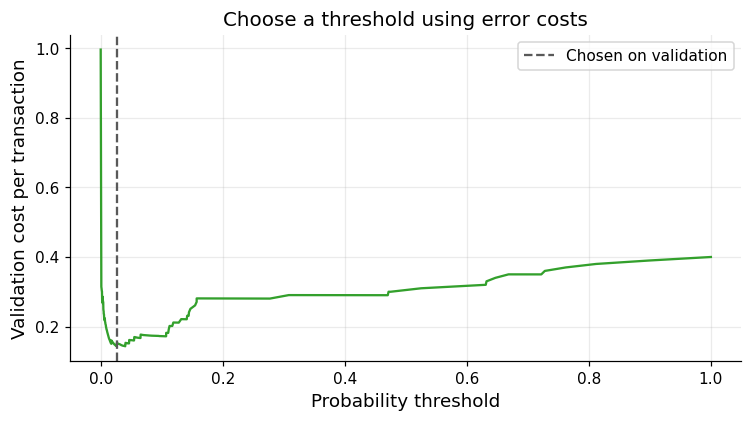

In [14]:
FALSE_POSITIVE_COST = 1
FALSE_NEGATIVE_COST = 100
rf_validation_scores = validation_scores["Random forest"]
candidate_thresholds = np.unique(np.r_[0.0, rf_validation_scores, 1.0])

cost_rows = []
for threshold in candidate_thresholds:
    predictions = (rf_validation_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()
    cost_per_transaction = (
        FALSE_POSITIVE_COST * fp + FALSE_NEGATIVE_COST * fn
    ) / len(y_val)
    cost_rows.append({
        "Threshold": threshold,
        "False positives": fp,
        "False negatives": fn,
        "Cost per transaction": cost_per_transaction,
    })

cost_curve = pd.DataFrame(cost_rows)
best_row = cost_curve.loc[cost_curve["Cost per transaction"].idxmin()]
best_threshold = float(best_row["Threshold"])
print(f"Validation-selected threshold: {best_threshold:.3f}")
print(f"Validation cost per transaction: {best_row['Cost per transaction']:.3f}")

fig, axis = plt.subplots(figsize=(7, 4))
axis.plot(
    cost_curve["Threshold"],
    cost_curve["Cost per transaction"],
    color=MODEL_COLORS["Random forest"],
)
axis.axvline(best_threshold, color="0.35", linestyle="--", label="Chosen on validation")
axis.set(xlabel="Probability threshold", ylabel="Validation cost per transaction", title="Choose a threshold using error costs")
axis.legend()
plt.tight_layout()
plt.show()

In [15]:
def threshold_metrics(y_true, scores, threshold):
    predictions = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "MCC": matthews_corrcoef(y_true, predictions),
        "False positives": fp,
        "False negatives": fn,
        "Cost per transaction": (FALSE_POSITIVE_COST * fp + FALSE_NEGATIVE_COST * fn) / len(y_true),
    }

pd.DataFrame([
    threshold_metrics(y_val, rf_validation_scores, 0.5),
    threshold_metrics(y_val, rf_validation_scores, best_threshold),
], index=["Default threshold", "Cost-selected threshold"]).round(3)

,Threshold,Accuracy,Precision,Recall,F1,MCC,False positives,False negatives,Cost per transaction
Default threshold,0.500,0.997,0.900,0.225,0.360,0.449,1,31,0.310
Cost-selected threshold,0.026,0.976,0.108,0.700,0.187,0.268,232,12,0.143


This chooses the threshold with the lowest observed validation cost; it does not guarantee the lowest future cost. In theory, the simple cost threshold $C_{FP}/(C_{FP}+C_{FN})$ applies when probabilities are calibrated and costs are fixed. The three models' probabilities need not be calibrated, so here we select empirically and keep the test set untouched.

## Final test evaluation

The model and threshold are now fixed. Evaluate once on the test set, which played no role in fitting the models, comparing curves, or choosing the threshold.

In [ ]:
rf_test_scores = models["Random forest"].predict_proba(X_test)[:, 1]
test_predictions = (rf_test_scores >= best_threshold).astype(int)
test_summary = threshold_metrics(y_test, rf_test_scores, best_threshold)
print(pd.Series(test_summary).round(3))

test_cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
fig, axis = plt.subplots(figsize=(5, 4))
image = axis.imshow(test_cm, cmap="Blues")
axis.set(
    xticks=[0, 1], yticks=[0, 1],
    xticklabels=["No fraud", "Fraud"],
    yticklabels=["No fraud", "Fraud"],
    xlabel="Predicted label", ylabel="Actual label",
    title="Test confusion matrix",
)
for row in range(2):
    for column in range(2):
        axis.text(column, row, f"{test_cm[row, column]:,}", ha="center", va="center", color="black")
fig.colorbar(image, ax=axis, label="Transactions")
plt.tight_layout()
plt.show()

## Tuning models responsibly

For parameter tuning, put learned preprocessing and the estimator in a scikit-learn `Pipeline`, then pass that pipeline to cross-validation, `GridSearchCV`, or `RandomizedSearchCV`. This makes each CV fold fit preprocessing only on its own training portion, preventing leakage. Search scores should reflect the goal (for example, average precision or a cost-sensitive scorer), and the untouched test set remains for the final evaluation. This synthetic dataset needs no preprocessing, and the models above use fixed settings.

## Takeaways

- With 0.4% fraud, a model can have high accuracy while detecting no fraud.
- Precision, recall, F1, and MCC describe different aspects of thresholded predictions; none expresses the application costs by itself.
- PR curves are especially informative for rare positives; ROC curves remain useful for ranking and false-positive-rate constraints.
- Choose the model and threshold using training/validation data and the real costs, then evaluate once on the test set.